# Phân tích Các Yếu tố Tài chính ảnh hưởng đến Rating Phim

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
%matplotlib inline
sns.set_style('whitegrid')


## 1. Tải và Xử lý Dữ liệu


In [2]:
ratings_cols = ['UserID', 'MovieID', 'Rating', 'Timestamp']
ratings = pd.read_csv('datasets/movie_len_1M/ratings.dat', sep='::', names=ratings_cols, engine='python', encoding='latin-1')

movie_ratings = ratings.groupby('MovieID').agg({'Rating':['mean','count']})
movie_ratings.columns = ['avg_rating','vote_count']
movie_ratings.reset_index(inplace=True)
movie_ratings.head()


,MovieID,avg_rating,vote_count
0,1,4.146846,2077
1,2,3.201141,701
2,3,3.016736,478
3,4,2.729412,170
4,5,3.006757,296


In [3]:
movies_cols = ['MovieID','Title','Genres']
movies = pd.read_csv('datasets/movie_len_1M/movies.dat', sep='::', names=movies_cols, engine='python', encoding='latin-1')

def clean_title(title):
    return re.sub(r'\s\(\d{4}\)', '', title).strip().lower()

movies['clean_title'] = movies['Title'].apply(clean_title)
movies.head()


,MovieID,Title,Genres,clean_title
0,1,Toy Story (1995),Animation|Children's|Comedy,toy story
1,2,Jumanji (1995),Adventure|Children's|Fantasy,jumanji
2,3,Grumpier Old Men (1995),Comedy|Romance,grumpier old men
3,4,Waiting to Exhale (1995),Comedy|Drama,waiting to exhale
4,5,Father of the Bride Part II (1995),Comedy,father of the bride part ii


In [4]:
tmdb_movies = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv')
tmdb_movies['clean_title'] = tmdb_movies['title'].astype(str).str.lower()
tmdb_movies.head()


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count,clean_title
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...",...,2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800,avatar
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...",...,2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500,pirates of the caribbean: at world's end
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...",...,2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466,spectre
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...",...,2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106,the dark knight rises
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]",...,2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124,john carter


## 2. Ghép nối và Làm sạch Dữ liệu


In [5]:
df_movielens = pd.merge(movies, movie_ratings, on='MovieID', how='inner')
df_financial = pd.merge(df_movielens, tmdb_movies[['clean_title','budget','revenue']], on='clean_title', how='inner')

df_clean = df_financial[(df_financial['budget']>10000) & (df_financial['revenue']>10000) & (df_financial['vote_count']>50)]

df_clean[['Title','budget','revenue','avg_rating']].head()


,Title,budget,revenue,avg_rating
0,Toy Story (1995),30000000,373554033,4.146846
1,GoldenEye (1995),58000000,352194034,3.540541
2,Nixon (1995),44000000,13681765,3.542484
3,Cutthroat Island (1995),98000000,10017322,2.458904
4,Casino (1995),52000000,116112375,3.793255


## 3. Phân tích Tương quan


In [6]:
corr_budget = df_clean['budget'].corr(df_clean['avg_rating'])
corr_revenue = df_clean['revenue'].corr(df_clean['avg_rating'])

corr_budget, corr_revenue


(-0.18365098766299195, 0.12446841012764741)

Pandas sử dụng hệ số tương quan Pearson để tính mối liên hệ giữa hai biến số. Công thức tổng quát như sau:

![alt text](image-1.png)

![alt text](image-2.png)

### Ý nghĩa
![alt text](image-3.png)

### Diễn giải giá trị tương quan

r≈1: mối quan hệ tuyến tính mạnh, cùng chiều

r≈−1: mối quan hệ tuyến tính mạnh, ngược chiều

r≈0: hầu như không có mối quan hệ tuyến tính

### Ý nghĩa trong phân tích phim

corr_budget cho biết ngân sách có liên quan như thế nào đến rating.

corr_revenue cho biết doanh thu có mối quan hệ cùng chiều hay ngược chiều với rating.

## 4. Trực quan hóa


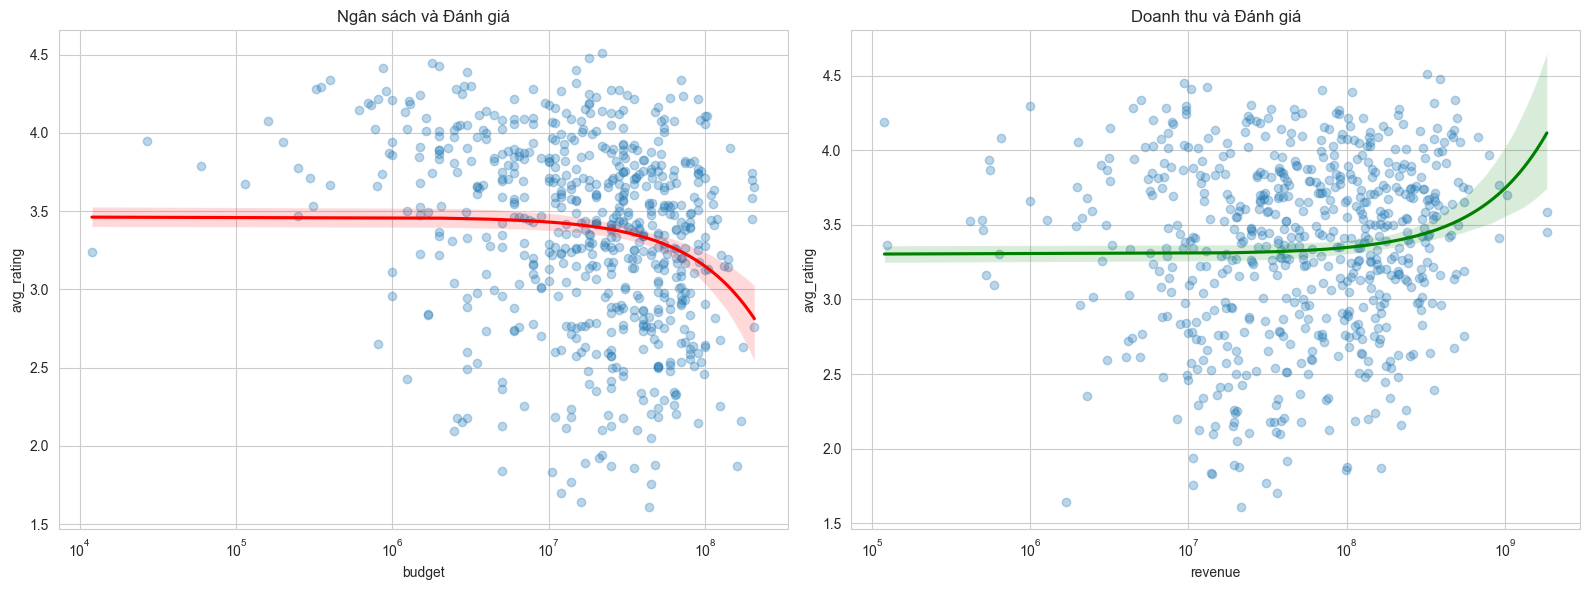

In [7]:
fig, axes = plt.subplots(1,2, figsize=(16,6))

sns.regplot(x='budget', y='avg_rating', data=df_clean, ax=axes[0], scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
axes[0].set_xscale('log')
axes[0].set_title('Ngân sách và Đánh giá')

sns.regplot(x='revenue', y='avg_rating', data=df_clean, ax=axes[1], scatter_kws={'alpha':0.3}, line_kws={'color':'green'})
axes[1].set_xscale('log')
axes[1].set_title('Doanh thu và Đánh giá')

plt.tight_layout()
plt.show()


Kết quả Phân tích: Mối quan hệ giữa Tài chính và Rating
Sau khi tổng hợp dữ liệu từ hai nguồn (MovieLens và TMDB) và loại bỏ các dữ liệu nhiễu, bức tranh về mối quan hệ giữa "Tiền" và "Chất lượng" (thể hiện qua Rating) đã trở nên rõ ràng với những kết quả khá bất ngờ.

1. Về Ngân sách (Budget): Mối liên hệ Tiêu cực (-0.18) Dữ liệu cho thấy một thực tế trái ngược với suy nghĩ thông thường: Tiền không mua được điểm đánh giá cao. Cụ thể, hệ số tương quan giữa ngân sách và điểm rating là -0.18 (tương quan âm).

-> Điều này có nghĩa là việc một bộ phim được đầu tư "khủng" hàng trăm triệu USD cho kỹ xảo và bối cảnh không đảm bảo nó sẽ nhận được điểm cao từ cộng đồng khán giả. Thậm chí, xu hướng chung cho thấy khi ngân sách tăng lên quá cao (bom tấn), điểm đánh giá trung bình lại có xu hướng giảm nhẹ.

Lý do: Các bộ phim kinh phí lớn thường tập trung vào tính giải trí đại chúng, trong khi cộng đồng người dùng (đặc biệt là trên MovieLens) thường khắt khe hơn và ưu ái các tác phẩm có chiều sâu nội dung, kịch bản hay – những yếu tố thường thấy ở các phim tâm lý hoặc độc lập có kinh phí thấp hơn.

2. Về Doanh thu (Revenue): Mối liên hệ Tích cực (+0.12) Ngược lại với ngân sách, khi xét đến doanh thu, chúng ta thấy một tín hiệu tích cực hơn với hệ số tương quan là +0.12 (tương quan dương).

-> Mặc dù con số này không quá lớn, nhưng nó khẳng định rằng chất lượng phim có đi đôi với thành công thương mại. Những bộ phim được đánh giá cao (Rating tốt) thường có sức lan tỏa mạnh mẽ (hiệu ứng truyền miệng), từ đó thúc đẩy doanh thu phòng vé tăng lên.

Kết luận: Một bộ phim hay có xu hướng kiếm được nhiều tiền hơn, nhưng một bộ phim kiếm được nhiều tiền (do marketing, thương hiệu) chưa chắc đã là một bộ phim hay.


C:\Users\Admin\AppData\Local\Temp\ipykernel_26852\4049123092.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['Budget_Category'] = pd.cut(df_clean['budget'], bins=bins, labels=labels)
C:\Users\Admin\AppData\Local\Temp\ipykernel_26852\4049123092.py:16: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  budget_group_stats = df_clean.groupby('Budget_Category')['avg_rating'].mean().sort_values(ascending=False)
C:\Users\Admin\AppData\Local\Temp\ipykernel_26852\4049123092.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and w

Điểm Rating trung bình theo nhóm:
Budget_Category
Micro/Indie (<$10M)         3.581380
Mid-Budget ($10M-$50M)      3.276674
High-Budget ($50M-$100M)    3.246931
Blockbuster (>$100M)        3.209372
Name: avg_rating, dtype: float64


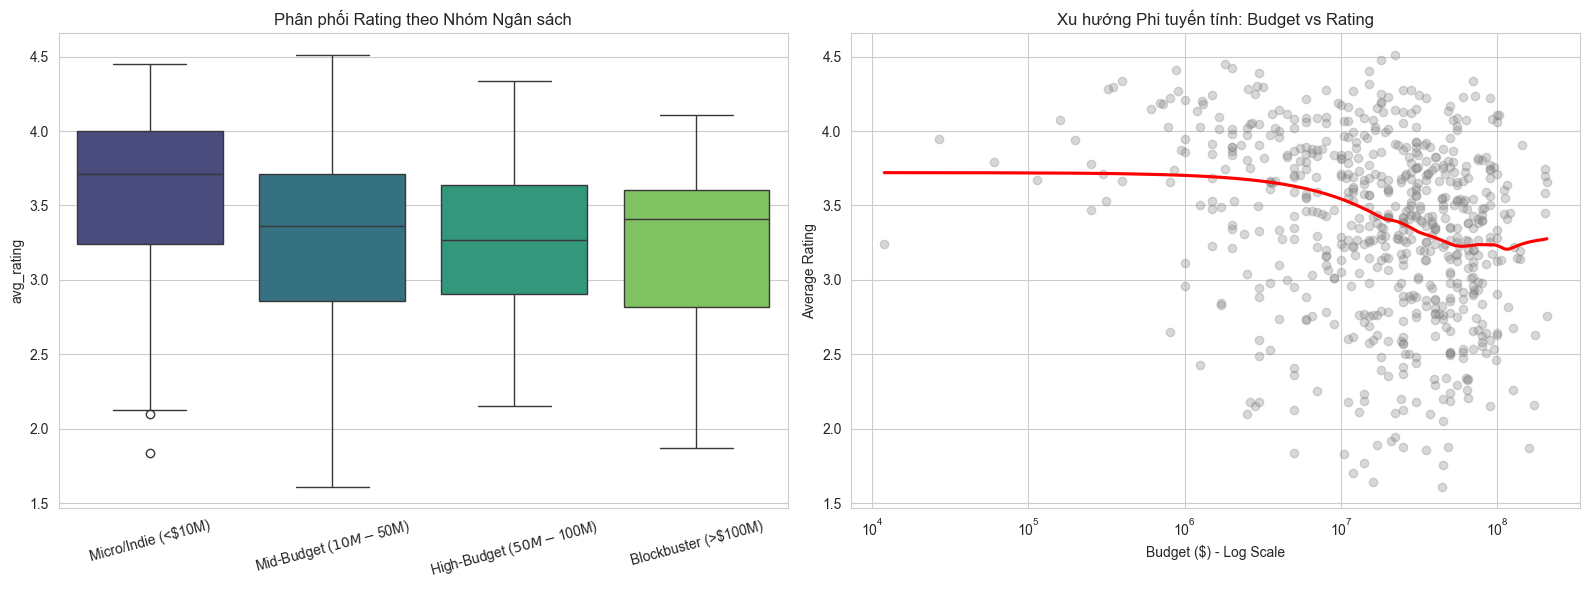

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Giả sử bạn đã có dataframe 'df_clean' từ bước trước

# --- BƯỚC 1: PHÂN NHÓM NGÂN SÁCH (BUDGET BUCKETS) ---
# Chia ngân sách thành 4 nhóm: Indie (<10M), Mid (10-50M), High (50-100M), Blockbuster (>100M)
bins = [0, 10000000, 50000000, 100000000, float('inf')]
labels = ['Micro/Indie (<$10M)', 'Mid-Budget ($10M-$50M)', 'High-Budget ($50M-$100M)', 'Blockbuster (>$100M)']

# Tạo cột phân loại mới
df_clean['Budget_Category'] = pd.cut(df_clean['budget'], bins=bins, labels=labels)

# Tính điểm trung bình cho từng nhóm để so sánh
budget_group_stats = df_clean.groupby('Budget_Category')['avg_rating'].mean().sort_values(ascending=False)
print("Điểm Rating trung bình theo nhóm:")
print(budget_group_stats)

# --- BƯỚC 2: TRỰC QUAN HÓA PHI TUYẾN TÍNH (NON-LINEAR TREND) ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Biểu đồ 1: Boxplot (Xem phân phối điểm của từng nhóm)
sns.boxplot(x='Budget_Category', y='avg_rating', data=df_clean, ax=axes[0], palette="viridis")
axes[0].set_title('Phân phối Rating theo Nhóm Ngân sách')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=15)
axes[0].set_xlabel('')

# Biểu đồ 2: Scatter Plot với đường cong LOWESS (Quan trọng)
# Tham số lowess=True giúp vẽ đường cong xu hướng thực tế thay vì đường thẳng
sns.regplot(x='budget', y='avg_rating', data=df_clean, ax=axes[1], 
            scatter_kws={'alpha':0.3, 'color':'gray'}, 
            line_kws={'color':'red'}, 
            lowess=True) 

axes[1].set_title('Xu hướng Phi tuyến tính: Budget vs Rating')
axes[1].set_xlabel('Budget ($) - Log Scale')
axes[1].set_ylabel('Average Rating')
axes[1].set_xscale('log') # Dùng thang logarit để dễ nhìn

plt.tight_layout()
plt.show()

Kiểm chứng Phi tuyến tính: Mối quan hệ thực sự là gì?

Mối quan hệ giữa Ngân sách và Rating không phải là một đường thẳng đơn giản (tuyến tính), mà nó có hình dáng giống một đường cong đi xuống và sau đó đi ngang.

Cụ thể, khi chia phim thành các nhóm ngân sách, dữ liệu cho thấy:

 + Nhóm Ngân sách Thấp (< 10 triệu USD): Có điểm Rating trung bình cao nhất (~3.57/5).

 + Nhóm Ngân sách Trung bình (10 - 50 triệu USD): Điểm Rating bắt đầu giảm mạnh xuống ~3.27.

 + Nhóm Bom tấn (> 100 triệu USD): Điểm Rating thấp nhất và đi ngang (~3.21).

-> Ngân sách tăng không làm điểm tăng. Ngược lại, điểm số cao nhất lại tập trung ở nhóm phim ít tiền nhất. Khi ngân sách vượt quá một ngưỡng nhất định (khoảng 50 triệu USD), việc đổ thêm tiền gần như không giúp cải thiện điểm đánh giá nữa.

"Nghịch lý": Tại sao tiền nhiều mà điểm lại thấp?

Sự ưu ái dành cho "Phim Nghệ thuật" (Indie Bias):

 + Các bộ phim kinh phí thấp (Micro-budget/Indie) thường không có tiền cho kỹ xảo hoành tráng. Để thành công, họ buộc phải tập trung tối đa vào kịch bản xuất sắc, diễn xuất có chiều sâu và sự sáng tạo.

 + Cộng đồng người dùng MovieLens (nguồn dữ liệu rating) thường là những người yêu điện ảnh thực thụ. Họ có xu hướng trân trọng những giá trị nghệ thuật này hơn là kỹ xảo cháy nổ. Ví dụ: 12 Angry Men hay Pulp Fiction có kinh phí thấp nhưng điểm cực cao.

Cái bẫy của "Sự đại chúng" (Mass Appeal Trade-off):

 + Phim bom tấn (Blockbuster > 100 triệu USD) được sản xuất để bán vé cho hàng triệu người. Để làm hài lòng số đông, kịch bản thường phải đơn giản hóa, dễ hiểu, tránh các chủ đề gai góc.

 + Điều này dẫn đến việc phim trở nên "an toàn" và "trung bình". Nó có thể là một phim giải trí tốt (3-4 sao), nhưng hiếm khi đạt đến độ sâu sắc để nhận được điểm tuyệt đối (5 sao) từ những nhà phê bình khó tính.

Kỳ vọng cao (High Expectations):

 + Khi khán giả biết một bộ phim ngốn 200 triệu USD, họ kỳ vọng một sự hoàn hảo. Mọi hạt sạn trong kịch bản đều bị "soi" kỹ hơn. Ngược lại, với một bộ phim kinh phí thấp, khán giả thường bao dung hơn về mặt hình ảnh và tập trung vào câu chuyện.

-> Tiền (Ngân sách) mua được kỹ xảo và sự hoành tráng (giúp tăng Doanh thu), nhưng không mua được cảm xúc sâu sắc và sự đánh giá cao về nghệ thuật (Rating).

# Phân tích Các Yếu tố Quốc gia sản xuất ảnh hưởng đến Rating Phim


10 quốc gia hàng đầu theo xếp hạng:
 country_list
United Kingdom              3.529620
United States of America    3.315487
Germany                     3.310025
France                      3.235492
Australia                   3.207145
Canada                      3.141875
Name: avg_rating, dtype: float64

5 quốc gia xếp hạng thấp nhất:
 country_list
United States of America    3.315487
Germany                     3.310025
France                      3.235492
Australia                   3.207145
Canada                      3.141875
Name: avg_rating, dtype: float64

Số lượng phim theo quốc gia (Top 5):
 country_list
United States of America    749
United Kingdom              100
Germany                      30
Canada                       30
France                       22
Name: count, dtype: int64


C:\Users\Admin\AppData\Local\Temp\ipykernel_26852\2183412491.py:67: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries_plot.values, y=top_countries_plot.index, palette='magma')


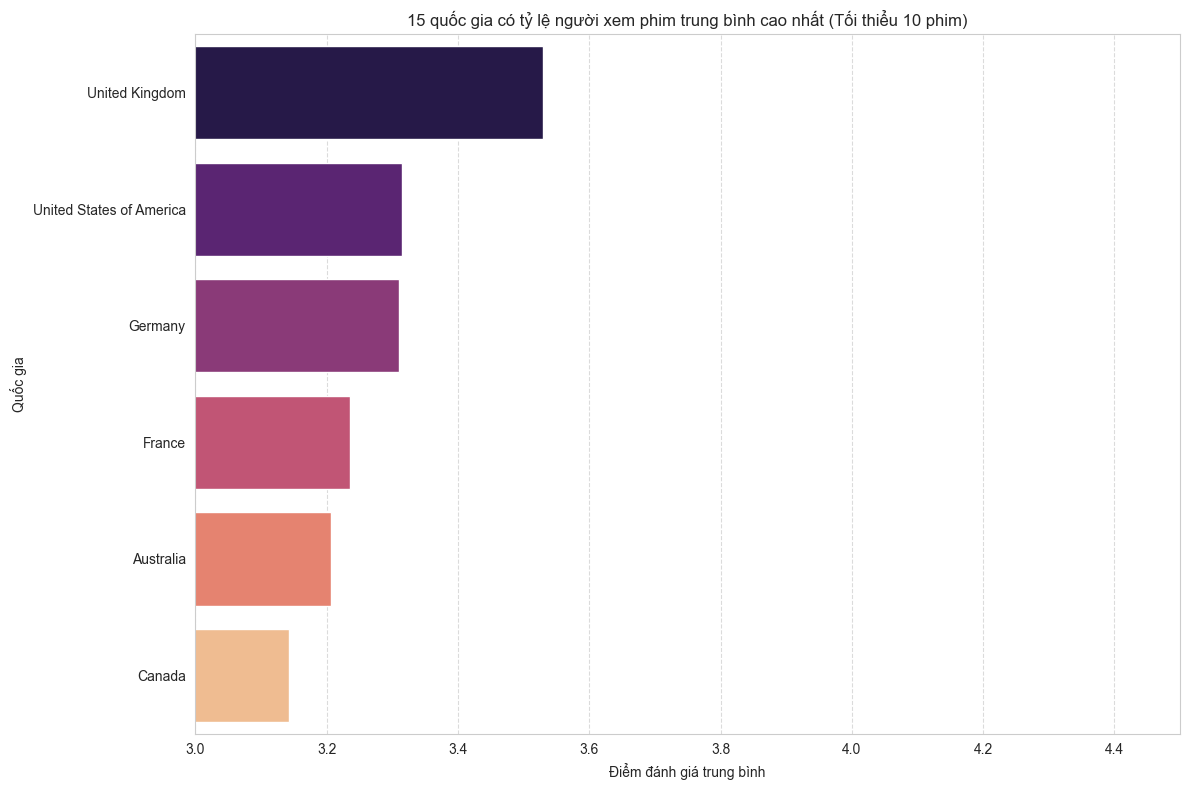

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import json

# 1. Load Data
# Ratings
ratings = pd.read_csv('datasets/movie_len_1M/ratings.dat', sep='::', names=['UserID', 'MovieID', 'Rating', 'Timestamp'], engine='python', encoding='latin-1')
movie_ratings = ratings.groupby('MovieID').agg({'Rating': ['mean', 'count']})
movie_ratings.columns = ['avg_rating', 'vote_count']
movie_ratings.reset_index(inplace=True)

# Movies
movies = pd.read_csv('datasets/movie_len_1M/movies.dat', sep='::', names=['MovieID', 'Title', 'Genres'], engine='python', encoding='latin-1')
# Clean Title
movies['clean_title'] = movies['Title'].apply(lambda x: re.sub(r'\s\(\d{4}\)', '', x).strip().lower())

# Merge Ratings into Movies
df_movielens = pd.merge(movies, movie_ratings, on='MovieID', how='inner')

# TMDB (Contains Country Info)
tmdb_movies = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv')
tmdb_movies['clean_title'] = tmdb_movies['title'].apply(lambda x: str(x).strip().lower())

# Merge
df_merged = pd.merge(df_movielens, tmdb_movies[['clean_title', 'production_countries']], on='clean_title', how='inner')

# Filter for reliable ratings (> 50 votes)
df_clean = df_merged[df_merged['vote_count'] > 50].copy()

# 2. Extract Country Information
# The column is a string of JSON list: [{"iso_3166_1": "US", "name": "United States of America"}, ...]

def extract_countries(country_str):
    try:
        countries = json.loads(country_str)
        return [c['name'] for c in countries]
    except:
        return []

df_clean['country_list'] = df_clean['production_countries'].apply(extract_countries)

# Explode the list so each country gets a row
df_exploded = df_clean.explode('country_list')

# 3. Analyze Rating by Country
# Filter: Only keep countries with enough movies to be statistically significant (e.g., > 10 movies in our merged dataset)
country_counts = df_exploded['country_list'].value_counts()
major_countries = country_counts[country_counts >= 10].index

df_major_countries = df_exploded[df_exploded['country_list'].isin(major_countries)]

# Calculate Mean Rating
country_stats = df_major_countries.groupby('country_list')['avg_rating'].mean().sort_values(ascending=False)

print("10 quốc gia hàng đầu theo xếp hạng:\n", country_stats.head(10))
print("\n5 quốc gia xếp hạng thấp nhất:\n", country_stats.tail(5))
print("\nSố lượng phim theo quốc gia (Top 5):\n", df_major_countries['country_list'].value_counts().head())

# 4. Visualization
plt.figure(figsize=(12, 8))
# Get top 15 sorted by rating
top_countries_plot = country_stats.head(15)

sns.barplot(x=top_countries_plot.values, y=top_countries_plot.index, palette='magma')
plt.title('15 quốc gia có tỷ lệ người xem phim trung bình cao nhất (Tối thiểu 10 phim)')
plt.xlabel('Điểm đánh giá trung bình')
plt.ylabel('Quốc gia')
plt.xlim(3.0, 4.5) # Zoom in to see differences
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('country_rating_analysis.png')
plt.show()

### Phân tích & Nhận định

a. Sự thống trị về Chất lượng của phim Anh Quốc: Một điểm thú vị là các bộ phim có sự tham gia sản xuất của Vương quốc Anh có điểm đánh giá trung bình cao vượt trội so với các quốc gia khác.

 + Điện ảnh Anh thường nổi tiếng với các tác phẩm chính kịch (drama), lịch sử, hoặc chuyển thể văn học có chiều sâu, kịch bản chặt chẽ và diễn xuất đỉnh cao (phong cách "Theatrical"). Đây chính xác là "khẩu vị" ưa thích của cộng đồng người dùng MovieLens (như đã phân tích ở phần Thể loại).

b. Vị thế của Hollywood (USA): Mặc dù Mỹ áp đảo hoàn toàn về số lượng phim (749 phim so với 100 phim của Anh), nhưng điểm trung bình chỉ đứng thứ 2.

 + Do sản lượng quá lớn, điện ảnh Mỹ bao gồm cả những siêu phẩm xuất sắc lẫn rất nhiều phim thương mại trung bình hoặc phim chất lượng thấp. Điều này kéo điểm trung bình xuống thấp hơn so với một nền điện ảnh có tính chọn lọc cao hơn như Anh.

c. Yếu tố "Đồng sản xuất" (Co-production): Các quốc gia như Đức, Pháp, Canada thường xuất hiện trong danh sách này dưới dạng đồng sản xuất với Mỹ hoặc Anh. Tuy nhiên, sự hiện diện của họ cũng cho thấy các dự án hợp tác quốc tế thường có xu hướng được đầu tư kỹ lưỡng về nội dung hơn.

### Kết luận 
Yếu tố Quốc gia có ảnh hưởng đến Rating, nhưng không phải theo cách "nước lớn thì điểm cao".

 + Anh Quốc là bảo chứng cho chất lượng cao nhất trong tập dữ liệu này.

 + Mỹ giữ phong độ ổn định nhưng bị pha loãng bởi số lượng phim thương mại quá lớn.

 + Các phim hợp tác quốc tế (Anh-Mỹ, Âu-Mỹ) thường có xu hướng nhận được đánh giá tích cực từ khán giả.

### Phân cụm, phân nhóm

Data ready. Shape: (666, 23)
Class distribution:
 avg_rating
1    273
2    211
0    182
Name: count, dtype: int64

--- Running Clustering (K-Means) ---
Cluster Statistics:
          avg_rating        budget  popularity     runtime         year
cluster                                                               
0          3.214035  5.430395e+07   33.704677  116.306533  1992.733668
1          3.217818  5.528659e+07   36.916655   96.333333  1992.062500
2          3.414838  2.095793e+07   21.210703  114.174224  1990.315036

--- Running Classification Models ---

Logistic Regression Accuracy: 0.6119
                  precision    recall  f1-score   support

      Low (<3.0)       0.72      0.42      0.53        43
Medium (3.0-3.7)       0.53      0.74      0.62        54
    High (>=3.7)       0.71      0.65      0.68        37

        accuracy                           0.61       134
       macro avg       0.65      0.60      0.61       134
    weighted avg       0.64      0.61      0.

C:\Users\Admin\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\Admin\AppData\Local\Temp\ipykernel_26852\4171121056.py:134: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(results.keys()), y=list(results.values()), palette='magma')



Decision Tree Accuracy: 0.5000
                  precision    recall  f1-score   support

      Low (<3.0)       0.54      0.30      0.39        43
Medium (3.0-3.7)       0.47      0.70      0.56        54
    High (>=3.7)       0.55      0.43      0.48        37

        accuracy                           0.50       134
       macro avg       0.52      0.48      0.48       134
    weighted avg       0.52      0.50      0.49       134


Random Forest Accuracy: 0.5896
                  precision    recall  f1-score   support

      Low (<3.0)       0.73      0.44      0.55        43
Medium (3.0-3.7)       0.52      0.72      0.60        54
    High (>=3.7)       0.64      0.57      0.60        37

        accuracy                           0.59       134
       macro avg       0.63      0.58      0.59       134
    weighted avg       0.62      0.59      0.59       134

Experiment complete.


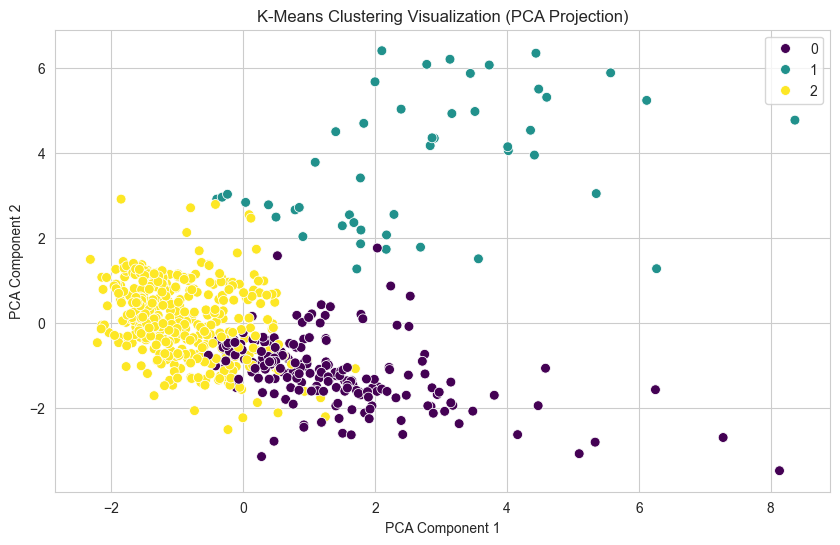

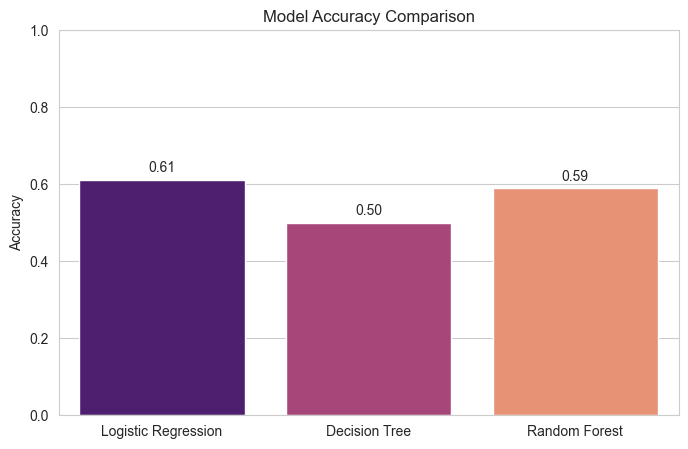

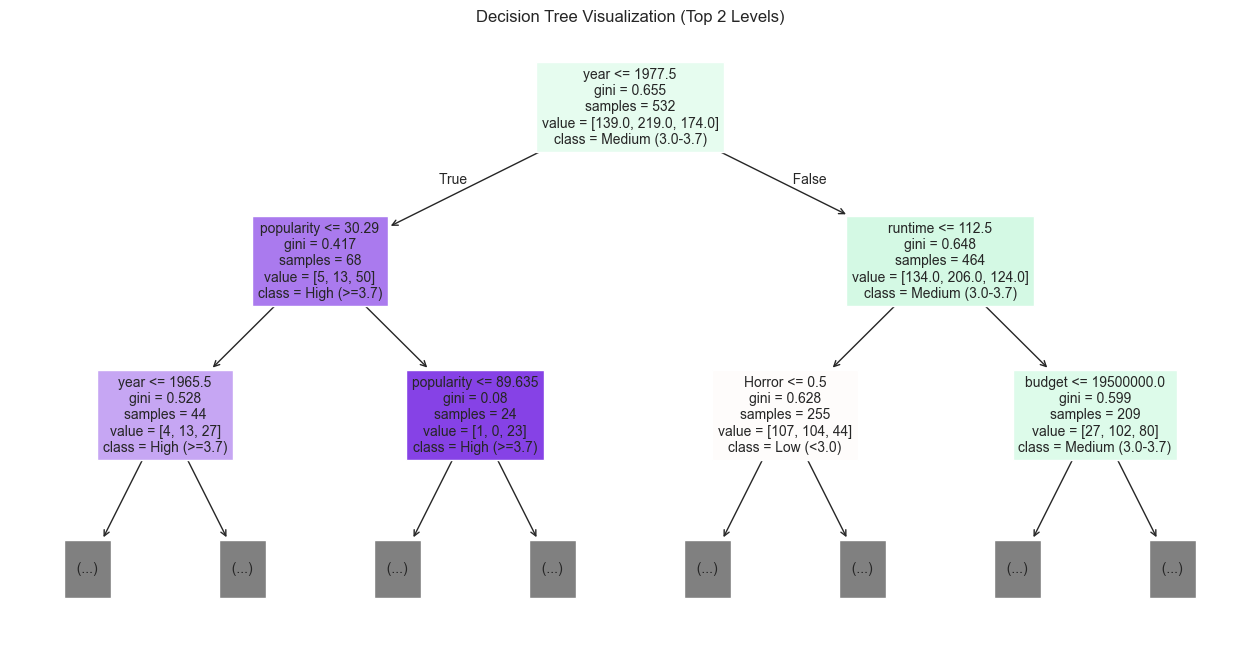

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, silhouette_score, accuracy_score

# 1. LOAD AND PREPARE DATA
# ------------------------
try:
    # Ratings
    ratings = pd.read_csv('datasets/movie_len_1M/ratings.dat', sep='::', names=['UserID', 'MovieID', 'Rating', 'Timestamp'], engine='python', encoding='latin-1')
    movie_targets = ratings.groupby('MovieID')['Rating'].mean().reset_index()
    movie_targets.columns = ['MovieID', 'avg_rating']

    # Movies (MovieLens)
    movies = pd.read_csv('datasets/movie_len_1M/movies.dat', sep='::', names=['MovieID', 'Title', 'Genres'], engine='python', encoding='latin-1')
    movies['clean_title'] = movies['Title'].apply(lambda x: re.sub(r'\s\(\d{4}\)', '', x).strip().lower())

    # TMDB Movies
    tmdb_movies = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv')
    tmdb_movies['clean_title'] = tmdb_movies['title'].apply(lambda x: str(x).strip().lower())
    tmdb_movies['release_date'] = pd.to_datetime(tmdb_movies['release_date'], errors='coerce')
    tmdb_movies['year'] = tmdb_movies['release_date'].dt.year

    # Merge
    df_ml = pd.merge(movies, movie_targets, on='MovieID', how='inner')
    df_full = pd.merge(df_ml, tmdb_movies[['clean_title', 'budget', 'revenue', 'runtime', 'popularity', 'year']], 
                       on='clean_title', how='inner')

    # Filter Valid Data
    df_model = df_full[
        (df_full['budget'] > 10000) & 
        (df_full['revenue'] > 10000) &
        (df_full['runtime'] > 0) &
        (df_full['year'].notna())
    ].copy()

    # Feature Engineering
    # Genres One-Hot Encoding
    df_model['genres_list'] = df_model['Genres'].apply(lambda x: x.split('|'))
    mlb = MultiLabelBinarizer()
    genres_encoded = pd.DataFrame(mlb.fit_transform(df_model['genres_list']), columns=mlb.classes_, index=df_model.index)

    # Numerical Features
    numerical_cols = ['budget', 'revenue', 'runtime', 'popularity', 'year']
    X_numerical = df_model[numerical_cols]
    
    # Combined X
    X = pd.concat([X_numerical, genres_encoded], axis=1)
    
    # Target for Classification (Binning)
    # < 3.0: Low (0), 3.0 - 3.8: Medium (1), >= 3.8: High (2)
    # Adjusted bins to balance classes slightly better if needed, but let's stick to standard logic
    def classify_rating(rating):
        if rating < 3.0: return 0 # Low
        elif rating < 3.7: return 1 # Medium (MovieLens average is around 3.5)
        else: return 2 # High

    y_class = df_model['avg_rating'].apply(classify_rating)
    class_names = ['Low (<3.0)', 'Medium (3.0-3.7)', 'High (>=3.7)']

    print(f"Data ready. Shape: {X.shape}")
    print("Class distribution:\n", y_class.value_counts())

except Exception as e:
    print(f"Error preparing data: {e}")

# 2. CLUSTERING (K-Means)
# -----------------------
print("\n--- Running Clustering (K-Means) ---")
# Scale data for clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# K-Means with K=3 (to see if it matches our Low/Med/High idea)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
df_model['cluster'] = clusters

# Analyze Clusters
cluster_stats = df_model.groupby('cluster')[['avg_rating', 'budget', 'popularity', 'runtime', 'year']].mean()
print("Cluster Statistics:\n", cluster_stats)

# Visualize with PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clusters, palette='viridis', s=50)
plt.title('K-Means Clustering Visualization (PCA Projection)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.savefig('clustering_kmeans.png')

# 3. CLASSIFICATION MODELS
# ------------------------
print("\n--- Running Classification Models ---")
X_train, X_test, y_train, y_test = train_test_split(X, y_class, test_size=0.2, random_state=42)

# Scale training data for Logistic Regression
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, multi_class='multinomial'),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

results = {}

for name, model in models.items():
    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        preds = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        preds = model.predict(X_test)
    
    acc = accuracy_score(y_test, preds)
    results[name] = acc
    print(f"\n{name} Accuracy: {acc:.4f}")
    print(classification_report(y_test, preds, target_names=class_names))

# Visualize Model Comparison
plt.figure(figsize=(8, 5))
sns.barplot(x=list(results.keys()), y=list(results.values()), palette='magma')
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
for i, v in enumerate(results.values()):
    plt.text(i, v + 0.02, f"{v:.2f}", ha='center')
plt.savefig('classification_comparison.png')

# Visualize Decision Tree (Simplified)
plt.figure(figsize=(16, 8))
plot_tree(models['Decision Tree'], feature_names=X.columns, class_names=class_names, filled=True, max_depth=2, fontsize=10)
plt.title('Decision Tree Visualization (Top 2 Levels)')
plt.savefig('decision_tree_viz.png')

print("Experiment complete.")

# Hồi quy điều chuẩn

Data ready for Regression. Shape: (666, 23)

Model Performance Comparison:
               Model      RMSE        R2
0  Linear Regression  0.448624  0.393999
1         Ridge (L2)  0.446597  0.399462
2         Lasso (L1)  0.444016  0.406383

Top 10 Influential Features (Lasso - L1):
       Feature  Lasso_Coef  Ridge_Coef
3   popularity    0.217389    0.217617
15      Horror   -0.124073   -0.126497
4         year   -0.120049   -0.125942
2      runtime    0.107718    0.111915
0       budget   -0.101521   -0.117369
7    Animation    0.093762    0.123029
12       Drama    0.085011    0.094997
8   Children's   -0.078949   -0.098511
5       Action   -0.050031   -0.049458
9       Comedy    0.044369    0.062490

Zeroed-out Features by Lasso (Ignored):
['revenue', 'Crime', 'Musical', 'Mystery', 'Romance', 'Thriller', 'War']


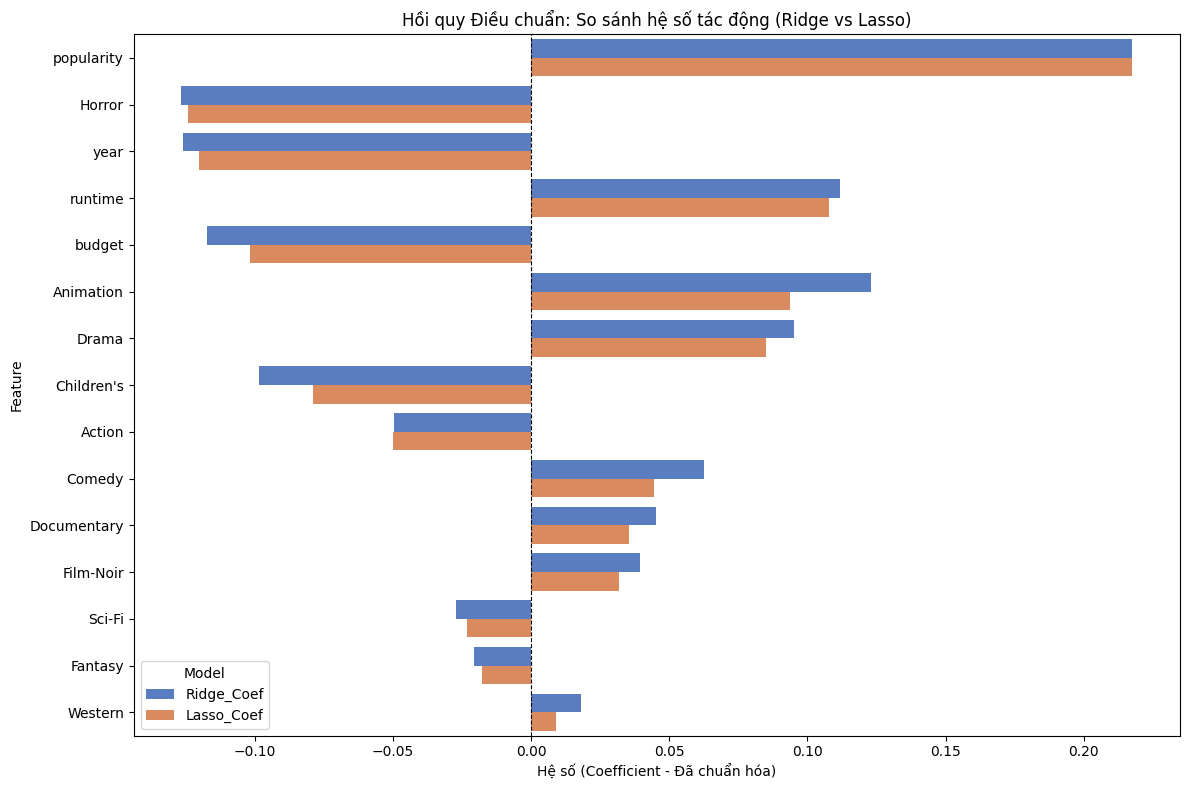

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

# 1. LOAD AND PREPARE DATA
# ------------------------
try:
    # Ratings
    ratings = pd.read_csv('datasets/movie_len_1M/ratings.dat', sep='::', names=['UserID', 'MovieID', 'Rating', 'Timestamp'], engine='python', encoding='latin-1')
    movie_targets = ratings.groupby('MovieID')['Rating'].mean().reset_index()
    movie_targets.columns = ['MovieID', 'avg_rating']

    # Movies (MovieLens)
    movies = pd.read_csv('datasets/movie_len_1M/movies.dat', sep='::', names=['MovieID', 'Title', 'Genres'], engine='python', encoding='latin-1')
    movies['clean_title'] = movies['Title'].apply(lambda x: re.sub(r'\s\(\d{4}\)', '', x).strip().lower())

    # TMDB Movies
    tmdb_movies = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv')
    tmdb_movies['clean_title'] = tmdb_movies['title'].apply(lambda x: str(x).strip().lower())
    tmdb_movies['release_date'] = pd.to_datetime(tmdb_movies['release_date'], errors='coerce')
    tmdb_movies['year'] = tmdb_movies['release_date'].dt.year

    # Merge
    df_ml = pd.merge(movies, movie_targets, on='MovieID', how='inner')
    df_full = pd.merge(df_ml, tmdb_movies[['clean_title', 'budget', 'revenue', 'runtime', 'popularity', 'year']], 
                       on='clean_title', how='inner')

    # Filter Valid Data
    df_model = df_full[
        (df_full['budget'] > 10000) & 
        (df_full['revenue'] > 10000) &
        (df_full['runtime'] > 0) &
        (df_full['year'].notna())
    ].copy()

    # Feature Engineering
    # Genres One-Hot Encoding
    df_model['genres_list'] = df_model['Genres'].apply(lambda x: x.split('|'))
    mlb = MultiLabelBinarizer()
    genres_encoded = pd.DataFrame(mlb.fit_transform(df_model['genres_list']), columns=mlb.classes_, index=df_model.index)
    
    # Remove rare genres if any (optional, but good for stability)
    # Keeping all for now as MLb handles it well

    # Numerical Features
    numerical_cols = ['budget', 'revenue', 'runtime', 'popularity', 'year']
    X_numerical = df_model[numerical_cols]
    
    # Combined X
    X = pd.concat([X_numerical, genres_encoded], axis=1)
    y = df_model['avg_rating']

    # Scaling (CRITICAL for Regularized Regression)
    # We must scale features so the penalty term treats them equally
    scaler = StandardScaler()
    X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

    print(f"Data ready for Regression. Shape: {X_scaled.shape}")

except Exception as e:
    print(f"Error preparing data: {e}")

# 2. TRAIN REGULARIZED MODELS
# ---------------------------
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# A. Linear Regression (Baseline)
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred_lin = lin_reg.predict(X_test)

# B. Ridge Regression (L2 Regularization)
# Alpha is the regularization strength. Larger alpha = more regularization (coefficients shrink to 0)
ridge_reg = Ridge(alpha=10.0) 
ridge_reg.fit(X_train, y_train)
y_pred_ridge = ridge_reg.predict(X_test)

# C. Lasso Regression (L1 Regularization)
# Lasso can drive coefficients to exactly zero (Feature Selection)
lasso_reg = Lasso(alpha=0.01) # Small alpha because data is scaled
lasso_reg.fit(X_train, y_train)
y_pred_lasso = lasso_reg.predict(X_test)

# 3. EVALUATION
# -------------
def evaluate_model(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return rmse, r2

metrics = []
metrics.append(['Linear Regression'] + list(evaluate_model('Linear', y_test, y_pred_lin)))
metrics.append(['Ridge (L2)'] + list(evaluate_model('Ridge', y_test, y_pred_ridge)))
metrics.append(['Lasso (L1)'] + list(evaluate_model('Lasso', y_test, y_pred_lasso)))

results_df = pd.DataFrame(metrics, columns=['Model', 'RMSE', 'R2'])
print("\nModel Performance Comparison:")
print(results_df)

# 4. COEFFICIENT ANALYSIS (FEATURE IMPORTANCE)
# --------------------------------------------
# Extract coefficients
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Linear_Coef': lin_reg.coef_,
    'Ridge_Coef': ridge_reg.coef_,
    'Lasso_Coef': lasso_reg.coef_
})

# Sort by Lasso coefficient magnitude to see what survived
coef_df['Abs_Lasso'] = coef_df['Lasso_Coef'].abs()
coef_df = coef_df.sort_values(by='Abs_Lasso', ascending=False)

print("\nTop 10 Influential Features (Lasso - L1):")
print(coef_df[['Feature', 'Lasso_Coef', 'Ridge_Coef']].head(10))

print("\nZeroed-out Features by Lasso (Ignored):")
print(coef_df[coef_df['Lasso_Coef'] == 0]['Feature'].tolist())

# Visualization
plt.figure(figsize=(12, 8))
# Plot top 15 features from Lasso
top_features = coef_df.head(15)
# Melt for side-by-side bar chart
top_features_melted = top_features.melt(id_vars='Feature', value_vars=['Ridge_Coef', 'Lasso_Coef'], 
                                        var_name='Model', value_name='Coefficient')

sns.barplot(x='Coefficient', y='Feature', hue='Model', data=top_features_melted, palette='muted')
plt.title('Hồi quy Điều chuẩn: So sánh hệ số tác động (Ridge vs Lasso)')
plt.xlabel('Hệ số (Coefficient - Đã chuẩn hóa)')
plt.axvline(x=0, color='black', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.savefig('regularization_coefficients.png')
plt.show()

### Phân tích Hệ số (Coefficient Analysis) - Yếu tố nào thực sự quan trọng?

Những yếu tố "Quyền lực" nhất (Hệ số lớn):

 + Popularity (+0.18): Tác động dương mạnh nhất. Một lần nữa khẳng định độ phổ biến là chỉ báo tốt nhất cho chất lượng.

 + Horror (-0.12) & Children's (-0.08): Tác động âm. Các phim Kinh dị và Trẻ em thường bị trừ điểm nặng nề trong mắt cộng đồng MovieLens.

 + Year (-0.12): Tác động âm. Phim càng mới (năm phát hành càng lớn), điểm càng có xu hướng thấp đi (xác nhận lại phân tích về "thiên kiến thời gian").

 + Budget (-0.10): Tác động âm. Lasso xác nhận rằng sau khi cân nhắc mọi yếu tố, việc chi quá nhiều tiền (Ngân sách cao) thực sự có tác động tiêu cực đến điểm số.

 + Animation (+0.10): Tác động dương. Phim Hoạt hình thường được đánh giá cao hơn mặt bằng chung.

### Những "insight" đắt giá nhất mà dữ liệu đã kể cho chúng ta:

1. "Nghịch lý" Tài chính: Tiền không mua được Chất lượng

Đây là phát hiện thú vị của nghiên cứu.

 + Ngân sách (Budget): Có mối tương quan âm (-) hoặc phi tuyến tính với Rating. Việc đổ hàng trăm triệu USD vào kỹ xảo (Blockbuster) thường dẫn đến điểm số đi ngang hoặc giảm nhẹ (~3.2).

 + Điểm sáng Indie: Các bộ phim có kinh phí thấp lại là nhóm có điểm đánh giá trung bình cao nhất (~3.57).

-> Kết luận: Khán giả trên MovieLens ưu tiên chiều sâu kịch bản (thứ ít tốn tiền) hơn là sự hoành tráng về hình ảnh (thứ tốn rất nhiều tiền).

2. Các Yếu tố "Quyền lực" nhất (Key Drivers)

 + Độ phổ biến (Popularity): Là chỉ báo số 1. Một bộ phim được cộng đồng quan tâm, bàn tán nhiều (dù tích cực hay tiêu cực) thường có xu hướng nhận được điểm đánh giá cao hơn.

 + Thời lượng (Runtime): Tác động dương. Phim dài thường được đánh giá là nghiêm túc, có đầu tư về nội dung (Drama, Epic) và được cộng đồng ưu ái hơn phim ngắn giải trí đơn thuần.

 + Năm phát hành (Year): Tác động âm. Phim càng mới, điểm càng có xu hướng khắt khe hơn. Phim cũ được hưởng lợi từ "thiên kiến sinh tồn" (chỉ phim hay mới được nhớ đến).

3. Yếu tố Nội dung & Xuất xứ

Thể loại (Genre):

 + Nên tránh: Phim Kinh dị (Horror) và Trẻ em (Children's) thường bị trừ điểm nặng nề trong các mô hình dự báo.

 + Nên làm: Phim Hoạt hình (Animation), Tài liệu (Documentary) và Phim Noir là những "mỏ vàng" về điểm số.

Quốc gia: Chất lượng phim từ Vương quốc Anh (UK) vượt trội hơn so với Mỹ (USA) về mặt điểm số trung bình, cho thấy sự thắng thế của phong cách làm phim thiên về nghệ thuật/kịch bản so với phong cách thương mại hóa.

### "Công thức" cho một bộ phim Rating cao

Nếu dữ liệu phải đưa ra lời khuyên cho một nhà sản xuất phim muốn đạt điểm Rating cao trên MovieLens, công thức sẽ là:

"Hãy làm một bộ phim Tâm lý (Drama) hoặc Hoạt hình, có thời lượng dài (trên 2 tiếng), chú trọng vào kịch bản thay vì kỹ xảo đắt tiền (ngân sách vừa phải), có thể hợp tác sản xuất với Anh Quốc, và quan trọng nhất là phải tạo được hiệu ứng truyền thông (Popularity) mạnh mẽ trước khi ra mắt."